# Barnstable and Long-Run Risk

## HBS Case

### *The Risk of Stocks in the Long-Run: The Barnstable College Endowment*

***

# 2. Estimating Underperformance

### Data

Use the returns on the S&P 500 ($r^m$) and 1-month T-bills, ($r^f$) provided in `barnstable_analysis_data.xlsx`.
* Data goes through `END_YR=2025`.

Barnstable's estimates of mean and volatility are based on the subsample of 1965 to 1999.
* We consider this subsample, as well as 2000-{END_YR}, as well as the full sample of 1926-{END_YR}.

### Notation

* $r$ = level return rates
* $R$ = cumulative return factor
* $\texttt{r}$ = log return rates

$$ R \equiv 1+r$$

$$ \texttt{r} \equiv \ln(1+r) = \ln(R)$$

### 1. Summary Statistics

Report the following (annualized) statistics.

| | 1965-1999 | | | 2000-2025 | | | 1926-2025 | |
|---|---|---|---|---|---|---|---|---|
| | mean | vol | | mean | vol | | mean | vol |
| **levels** | $r^m$ | | | | | | | |
| | $\tilde{r}^m$ | | | | | | | |
| | $r^f$ | | | | | | | |
| **logs** | $\texttt{r}^m$ | | | | | | | |
| | $\tilde{\texttt{r}}^m$ | | | | | | | |
| | $\texttt{r}_f$ | | | | | | | |

* Comment on how the full-sample return stats compare to the sub-sample stats.
* Comment on how the level stats compare to the log stats.

In [19]:
import pandas as pd
import numpy as np
path = "data/barnstable_analysis_data.xlsx"
barnstable = pd.read_excel(path, sheet_name="data")
barnstable['date'] = pd.to_datetime(barnstable['date'])

barnstable['rf'] = barnstable['TB1M']
barnstable['rm'] = barnstable['SPX']
barnstable['rm excess'] = barnstable['rm'] - barnstable['rf']
barnstable['log rf'] = np.log1p(barnstable['rf'])
barnstable['log rm'] = np.log1p(barnstable['rm'])
barnstable['log rm excess'] = np.log1p(barnstable['rm excess'])

sub_sample1 = barnstable[(barnstable['date'].dt.year >= 1965) & (barnstable['date'].dt.year <= 1999)]
sub_sample2 = barnstable[(barnstable['date'].dt.year >= 2000) & (barnstable['date'].dt.year <= 2025)]
full_sample = barnstable[(barnstable['date'].dt.year >= 1926) & (barnstable['date'].dt.year <= 2025)]

relevant_cols = ['rm excess', 'log rm excess', 'rf', 'log rf','rm', 'log rm']
#annualize mean
#helper 
summary = pd.DataFrame({
    ('1965-1999', 'mean'): sub_sample1[relevant_cols].mean() * 12,
    ('1965-1999', 'vol'): sub_sample1[relevant_cols].std() * np.sqrt(12),
    ('2000-2025', 'mean'): sub_sample2[relevant_cols].mean() * 12,
    ('2000-2025', 'vol'): sub_sample2[relevant_cols].std() * np.sqrt(12),
    ('1926-2025', 'mean'): full_sample[relevant_cols].mean() * 12,
    ('1926-2025', 'vol'): full_sample[relevant_cols].std() * np.sqrt(12),
})
print(summary)

              1965-1999           2000-2025           1926-2025          
                   mean       vol      mean       vol      mean       vol
rm excess      0.067873  0.150120  0.072555  0.151621  0.084272  0.186322
log rm excess  0.056395  0.151095  0.060819  0.152729  0.066817  0.185900
rf             0.061482  0.007172  0.018269  0.005573  0.031831  0.008446
log rf         0.061299  0.007125  0.018240  0.005562  0.031753  0.008412
rm             0.129354  0.149405  0.090824  0.151383  0.116102  0.186030
log rm         0.117600  0.149568  0.079031  0.152302  0.098503  0.185323


Comparing the 2 subsamples versus the full sample, I see that the market return falls from 0.129 to 0.09 after 1999, but excess return doesn't decrease much which tells me that the T-bill rates coallapsed as evident in the change in mean from 0.061 to 0.018 for "rf" row. Volatility across these subsamples are pretty similar, however the excess return and volatility for excess returns for the full sample are higher than both subsamples. This indicates that it is likely that excess returns were higher before 1965 which isn't captured in the subsamples. 

Comparing the log level to regular level, log mean returns are consitently lower than regular level means (by about 1.2% in subsample and 1.8% in full sample). The difference is larger in the full sample because that is the more volatile range compared to the 2 subsamples.

### 2. Probability of Underperformance

Recall the following:
- If $x\sim\mathcal{N}\left(\mu_x,\sigma_x^2\right)$, then

  $$\Pr\left[x<\ell\right] = \Phi_\mathcal{N}\left(L\right)$$

  where $L = \frac{\ell-\mu_x}{\sigma_x}$ and $\Phi_\mathcal{N}$ denotes the standard normal cdf.

- Remember that cumulative log returns are simply the sum of the single-period log returns:
  
  $$\texttt{r}^m_{t,t+h} \equiv \sum_{i=1}^h \texttt{r}^m_{t+i}$$

- It will be convenient to use and denote sample averages. We use the following notation for an $h$-period average ending at time $t+h$:
  
  $$\bar{\texttt{r}}^m_{t,t+h} = \frac{1}{h}\sum_{i=1}^h \texttt{r}^m_{t+i}$$

Calculate the probability that the cumulative market return will fall short of the cumulative risk-free return:

$$\Pr\left[R^m_{t,t+h} < R^f_{t,t+h}\right]$$

To analyze this analytically, convert the probability statement above to a probability statement about mean log returns.

#### 2.1
Calculate the probability using the subsample 1965-1999.

In [ ]:
from scipy.stats import norm
def calc_prob(h):
    mu = summary.loc['log rm excess', ('1965-1999', 'mean')]
    sd = summary.loc['log rm excess', ('1965-1999', 'vol')]
    L = (np.sqrt(h) *(0 - mu)) / sd
    return norm.cdf(L)




#### 2.2
Report the precise probability for $h=15$ and $h=30$ years.

In [14]:
for h in (15,30):
    print(f"probability for h = {h}: {calc_prob(h)}")

probability for h = 15: 2.423205921202563e-41
probability for h = 30: 1.4078421523096542e-80



#### 2.3
Plot the probability as a function of the investment horizon, $h$, for $0<h\le 30$ years.

**Hint**: The probability can be expressed as:

$$p(h) = \Phi_{\mathcal{N}}\left(-\sqrt{h}\;\text{SR}\right)$$

where $\text{SR}$ denotes the sample Sharpe ratio of **log** market returns.

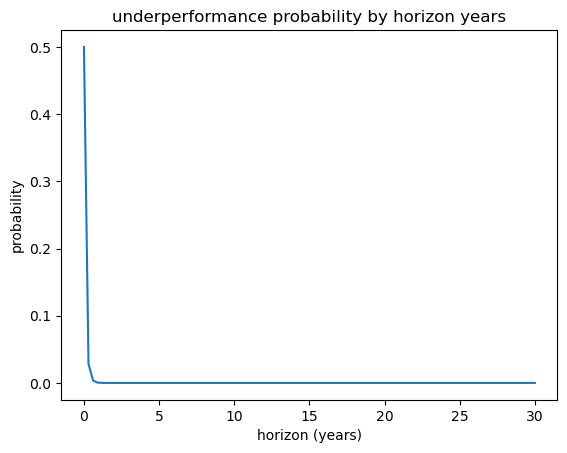

In [15]:
import matplotlib.pyplot as plt
h = np.linspace(0, 30, 100)
plt.plot(h, calc_prob(h))
plt.xlabel("horizon (years)")
plt.ylabel("probability")
plt.title("underperformance probability by horizon years")
plt.show()

### 3. Full Sample Analysis

Use the sample 1965-{END_YR} to reconsider the 30-year probability. As of the end of {END_YR}, calculate the probability of the stock return underperforming the risk-free rate over the next 30 years. That is, $R^m_{t,t+h}$ underperforming $R^f_{t,t+h}$ for $0<h\le 30$.

### 4. In-Sample Estimate of Out-of-Sample Likelihood

Let's consider how things turned out relative to Barnstable's 1999 expectations.

What was the probability (based on the 1999 estimate of $\mu$) that the `h`-year market return, $R^m_{t,t+h}$, would be smaller than that realized in `2000-{END_YR}`? 

**Hint**: You can calculate this as:

$$p = \Phi_{\mathcal{N}}\left(\sqrt{h}\; \frac{\bar{\texttt{r}}_{out-of-sample} - \bar{\texttt{r}}_{\text{in-sample}}}{\sigma_{\text{in-sample}}}\right)$$

where "in-sample" denotes 1965-1999 and "out-of-sample" denotes 2000-{END_YR}.